# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 6: Comparativo Multimodelo com o Extrator LOFAR (MLP, CNN, SVM, Random Forest e BiGRU)

Neste notebook comparamos as famílias de aprendizado de máquina avaliadas no projeto com o **LOFAR** (*Low Frequency Analysis and Recording*): espectro de magnitude com `n_pts = 1024` bins (resolução de ~7,8 Hz até 8 kHz), normalizado pelo TPSW (*Two-Pass Split Window*), que realça as raias tonais de máquinas e hélice sobre o ruído de fundo (detalhes no Notebook 5). É o mesmo formato dos notebooks 9 (DEMON) e 11 (HHT), com o LOFAR no lugar do extrator.

| Modelo | Experimento | Grade temporal | Origem |
| :--- | :--- | :---: | :--- |
| MLP (≈ artigo) | `mlp_lofar` | 0,512 s | pipeline iara, `test_scripts/mlp_lofar.py`: como o MLP MEL, mas com dropout 0,2 (artigo: 0); paciência 16 e até 512 épocas (artigo: 8 e 50) |
| SVM Nyström m=6000 | `svm_nystroem_6000_lofar_elasticnet_l1r0.15` | 0,512 s | pipeline iara (`test_scripts/svm.py`), ElasticNet l1_ratio=0,15 |
| Random Forest 100 árv. | `rf_lofar5s_n100_balanced_4c` | 5,12 s | `scratch/generate_rf_predictions_and_analysis.py`, média de 10 quadros de 0,512 s |
| CNN (artigo) | `cnn_lofar` | 0,512 s | pipeline iara, `test_scripts/cnn_lofar.py`: configuração do grid search do artigo (conv 512/128, ReLU, max pooling 4×2, dropout 0,4, lr 1e-6, imagens de 32 janelas com 50% de sobreposição, paciência 32) |
| CNN 2D ad hoc | `cnn2d_lofar5s_w32_b64_e15_4c` | 5,12 s | `scratch/generate_cnn_predictions_and_analysis.py`, imagens de 32 vetores LOFAR de 5,12 s (colapsou; mantida só como referência) |
| BiGRU + atenção | `bigru_att_lofar5s_h128_s15-5_e15_4c` | 5,12 s | `scratch/eval_bigru_lofar_multiclass_5x2cv.py`, sequências de 15 vetores |

Todos os modelos foram avaliados no protocolo oficial de **$5\times2$ validação cruzada (10 folds)** com **particionamento por gravação de áudio (`ID`, `exclusive_header='ID'` em `src/iara/ml/experiment.py`)** — janelas de um mesmo arquivo nunca ficam em treino e teste ao mesmo tempo — sobre os **1.706 áudios de UO** do IARA (*Silva et al.*, IEEE Access 2025). O particionamento **não** isola navios: gravações diferentes do mesmo navio (`Ship ID`) podem cair em treino e teste.

> **Duas grades temporais.** Os modelos do pipeline oficial (MLP, CNN e SVM) classificam janelas de **0,512 s**; os modelos ad hoc de `scratch/` (RF, CNN 2D, MLP 5,12 s, BiGRU) usam o cache de **5,12 s** (média de 10 quadros), o mesmo dos notebooks DEMON e HHT. A predição por arquivo é sempre o voto majoritário das janelas, mas modelos de grades diferentes não diferem só no classificador.

> Todos os números são recalculados das predições por janela em `results/trainings/` por `notebooks/src/iara_results.py` (voto majoritário por arquivo, SP de `src/iara/ml/metrics.py`, **ACC = acurácia balanceada**, média ± desvio populacional nos 10 folds).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 120})

## 1. Tabela Mestra: LOFAR no Artigo e nas Re-execuções Locais

> **Notas metodológicas:**
> * **ACC = acurácia balanceada** (média dos recalls) em todas as tabelas, inclusive na Tabela 7 do artigo.
> * **Três modos, sempre rotulados:** `4c` (4 classes); `4c_sem_bg` (o mesmo modelo 4c avaliado só em navios, prever BACKGROUND = erro; os recalls por classe são os mesmos do 4c); `3c` (modelo **retreinado** sem BACKGROUND — só existe para BiGRU + atenção). Comparar `3c` com `4c_sem_bg` mistura problemas diferentes.
> * O artigo publica só SP, ACC e F1 médios (sem predições por fold); por isso não há F-test entre as re-execuções locais e o artigo.
> * **[COLAPSADA]** marca modelos com algum fold em que uma classe tem recall < 5%: CNN 2D ad hoc (SP por fold: 42,7, 38,8, 36,9, 0,0, 35,1, 45,5, 35,9, 37,9, 35,5, 45,6). A média desses modelos não é informativa e eles ficam fora das conclusões.

In [2]:
# ---- Experimentos em disco (results/trainings/{tests,multirep}); _3c = modelo RETREINADO sem BACKGROUND ----
REP = 'LOFAR'
OUTRA = 'MEL'
PRINCIPAIS = [
    ('MLP (≈ artigo)', 'mlp_lofar', None, '0,512 s', 'pipeline iara, `test_scripts/mlp_lofar.py`: como o MLP MEL, mas com dropout 0,2 (artigo: 0); paciência 16 e até 512 épocas (artigo: 8 e 50)'),
    ('SVM Nyström m=6000', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15', None, '0,512 s', 'pipeline iara (`test_scripts/svm.py`), ElasticNet l1_ratio=0,15'),
    ('Random Forest 100 árv.', 'rf_lofar5s_n100_balanced_4c', None, '5,12 s', '`scratch/generate_rf_predictions_and_analysis.py`, média de 10 quadros de 0,512 s'),
    ('CNN (artigo)', 'cnn_lofar', None, '0,512 s', 'pipeline iara, `test_scripts/cnn_lofar.py`: configuração do grid search do artigo (conv 512/128, ReLU, max pooling 4×2, dropout 0,4, lr 1e-6, imagens de 32 janelas com 50% de sobreposição, paciência 32)'),
    ('CNN 2D ad hoc', 'cnn2d_lofar5s_w32_b64_e15_4c', None, '5,12 s', '`scratch/generate_cnn_predictions_and_analysis.py`, imagens de 32 vetores LOFAR de 5,12 s (colapsou; mantida só como referência)'),
    ('BiGRU + atenção', 'bigru_att_lofar5s_h128_s15-5_e15_4c', 'bigru_att_lofar5s_h128_s15-5_e15_3c', '5,12 s', '`scratch/eval_bigru_lofar_multiclass_5x2cv.py`, sequências de 15 vetores'),
]  # (rótulo, exp 4c, exp 3c ou None, grade temporal, origem)
SVM_SWEEP = [
    ('m=1000', 'svm_nystroem_1000_lofar'),
    ('m=1000, C=2.0', 'svm_nystroem_1000_lofar_C2.0'),
    ('m=1000, C=2.0, PCA64', 'svm_nystroem_1000_lofar_pca64_C2.0'),
    ('m=2000', 'svm_nystroem_2000_lofar'),
    ('m=2000, C=0.1', 'svm_nystroem_2000_lofar_C0.1'),
    ('m=2000, C=2.0', 'svm_nystroem_2000_lofar_C2.0'),
    ('m=4000, C=2.0', 'svm_nystroem_4000_lofar_C2.0'),
    ('m=4000, C=0.5, ElasticNet', 'svm_nystroem_4000_lofar_elasticnet_l1r0.15_C0.5'),
    ('m=4000, C=2.0, PCA64, ElasticNet', 'svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C2.0'),
    ('m=4000, C=0.5, PCA64, ElasticNet', 'svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C0.5'),
    ('m=6000, ElasticNet', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'),
    ('m=6000, C=0.5, ElasticNet', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15_C0.5'),
    ('m=10000, ElasticNet', 'svm_nystroem_10000_lofar_elasticnet_l1r0.15'),
    ('m=10000, C=0.5, ElasticNet', 'svm_nystroem_10000_lofar_elasticnet_l1r0.15_C0.5'),
]
PARES_OUTRA = [
    ('MLP (≈ artigo, 0,512 s)', 'mlp_lofar', 'mlp'),
    ('CNN (artigo, 0,512 s)', 'cnn_lofar', 'cnn_mel_artigo'),
    ('SVM Nyström (melhor de cada)', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0'),
    ('Random Forest (5,12 s)', 'rf_lofar5s_n100_balanced_4c', 'rf_mel5s_n100_balanced_4c'),
    ('BiGRU + atenção (5,12 s)', 'bigru_att_lofar5s_h128_s15-5_e15_4c', 'bigru_att_mel5s_h64_s15-5_e20_4c'),
]  # (arquitetura, exp com REP, exp com OUTRA)
MET = ('SP', 'ACC', 'F1')

E4 = {l: e for l, e, *_ in PRINCIPAIS}
E3 = {l: e3 for l, _, e3, *_ in PRINCIPAIS if e3}
S4 = {l: R.summary(e, '4c') for l, e in E4.items()}
SB = {l: R.summary(e, '4c_sem_bg') for l, e in E4.items()}
S3 = {l: R.summary(e, '3c') for l, e in E3.items()}
FOLDS = {l: R.fold_metrics(e) for l, e in E4.items()}
# Colapso: em algum fold, alguma classe com recall < 5% (o SP do fold despenca e a média deixa de ser informativa)
COLAPSADO = {l: bool((FOLDS[l][[f'R_{c}' for c in R.CLASSES]].min(axis=1) < 5).any()) for l in E4}

# Tabela 7 do artigo (Silva et al., IEEE Access 2025): só SP, ACC e F1 em 4 classes
tab_artigo = pd.DataFrame([{'Modelo': f'{m} | {r} (Tabela 7 do artigo)',
                            **{k: R.fmt(v) for k, v in R.ARTICLE_TABLE7[(m, r)].items()}}
                           for (m, r) in R.ARTICLE_TABLE7 if r == REP]).set_index('Modelo')
ROWS = [(l + (' [COLAPSADA]' if COLAPSADO[l] else ''), e) for l, e in E4.items()]
tab_4c = R.table(ROWS, mode='4c', metrics=MET)
tab_4c.insert(len(MET), 'Grade', [g for *_, g, _ in PRINCIPAIS])
tab_sem_bg = R.table(ROWS, mode='4c_sem_bg', metrics=MET)
tab_3c = R.table([(l, e, '3c') for l, e in E3.items()], metrics=MET) if E3 else None
def _completo(e):
    try:
        R.fold_metrics(e)
        return True
    except FileNotFoundError:   # sem os 10 folds (ou CSVs com outro nome) em disco
        return False


SWEEP_FORA = [(l, e) for l, e in SVM_SWEEP if not _completo(e)]
SVM_SWEEP = [(l, e) for l, e in SVM_SWEEP if _completo(e)]
SWEEP = {l: R.summary(e) for l, e in SVM_SWEEP}
tab_sweep = R.table(SVM_SWEEP, metrics=MET)

print('Tabela 7 do artigo (4 classes):'); display(tab_artigo)
print('Avaliação local, 4 classes (modelos 4c):'); display(tab_4c)
print('Avaliação local, só navios, modelos 4c (prever BACKGROUND = erro):'); display(tab_sem_bg)
if tab_3c is not None:
    print('Só navios, modelos RETREINADOS sem BACKGROUND (3c):'); display(tab_3c)

Tabela 7 do artigo (4 classes):


,SP,ACC,F1
Modelo,,,
RF | LOFAR (Tabela 7 do artigo),56.92 ± 1.69,58.87 ± 1.68,58.00 ± 1.41
MLP | LOFAR (Tabela 7 do artigo),66.51 ± 1.39,67.48 ± 1.24,66.72 ± 1.17
CNN | LOFAR (Tabela 7 do artigo),66.05 ± 1.90,67.02 ± 1.78,66.29 ± 2.13


Avaliação local, 4 classes (modelos 4c):


,SP,ACC,F1,Grade,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,,
MLP (≈ artigo),66.24 ± 1.78,67.22 ± 1.65,66.42 ± 1.87,"0,512 s",46.35,61.48,74.72,86.33,mlp_lofar
SVM Nyström m=6000,63.83 ± 1.91,65.47 ± 1.77,63.58 ± 1.72,"0,512 s",38.15,60.40,76.31,87.04,svm_nystroem_6000_lofar_elasticnet_l1r0.15
Random Forest 100 árv.,63.07 ± 1.81,63.79 ± 1.70,64.92 ± 1.54,"5,12 s",47.81,55.64,75.79,75.92,rf_lofar5s_n100_balanced_4c
CNN (artigo),66.49 ± 1.28,67.29 ± 1.19,66.64 ± 1.37,"0,512 s",47.81,63.89,71.73,85.71,cnn_lofar
CNN 2D ad hoc [COLAPSADA],35.40 ± 12.38,47.58 ± 2.43,40.93 ± 4.25,"5,12 s",39.21,33.22,27.48,90.41,cnn2d_lofar5s_w32_b64_e15_4c
BiGRU + atenção,62.22 ± 1.09,62.66 ± 1.02,63.79 ± 0.91,"5,12 s",55.84,51.21,68.88,74.69,bigru_att_lofar5s_h128_s15-5_e15_4c


Avaliação local, só navios, modelos 4c (prever BACKGROUND = erro):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
MLP (≈ artigo),60.17 ± 2.12,60.85 ± 2.05,61.68 ± 1.91,46.35,61.48,74.72,mlp_lofar
SVM Nyström m=6000,56.96 ± 1.98,58.29 ± 1.75,59.18 ± 1.61,38.15,60.40,76.31,svm_nystroem_6000_lofar_elasticnet_l1r0.15
Random Forest 100 árv.,59.08 ± 2.19,59.75 ± 2.13,59.78 ± 2.04,47.81,55.64,75.79,rf_lofar5s_n100_balanced_4c
CNN (artigo),60.64 ± 1.67,61.14 ± 1.60,61.82 ± 1.48,47.81,63.89,71.73,cnn_lofar
CNN 2D ad hoc [COLAPSADA],25.09 ± 9.22,33.30 ± 3.70,30.12 ± 3.07,39.21,33.22,27.48,cnn2d_lofar5s_w32_b64_e15_4c
BiGRU + atenção,58.34 ± 1.50,58.64 ± 1.41,59.42 ± 1.46,55.84,51.21,68.88,bigru_att_lofar5s_h128_s15-5_e15_4c


Só navios, modelos RETREINADOS sem BACKGROUND (3c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
BiGRU + atenção,58.57 ± 2.24,58.85 ± 2.15,59.09 ± 2.20,57.42,50.67,68.46,bigru_att_lofar5s_h128_s15-5_e15_3c


### Leitura da Tabela Mestra
1. **Artigo:** SP com LOFAR na Tabela 7 — RF: 56,92 ± 1,69; MLP: 66,51 ± 1,39; CNN: 66,05 ± 1,90.
2. **Reprodução local do pipeline oficial:** MLP (≈ artigo) 66,24 ± 1,78% contra 66,51 ± 1,39% no artigo (diferença de -0,27 p.p., dentro de um desvio); CNN (artigo) 66,49 ± 1,28% contra 66,05 ± 1,90% no artigo (diferença de 0,44 p.p., dentro de um desvio).
3. **Ranking local (SP médio, 4c):** CNN (artigo) (66,49), MLP (≈ artigo) (66,24), SVM Nyström m=6000 (63,83), Random Forest 100 árv. (63,07), BiGRU + atenção (62,22), CNN 2D ad hoc (35,40).

## 2. Comparativo Global

Índice SP e acurácia balanceada (média ± desvio nos 10 folds) no problema de 4 classes, com as linhas de referência da Tabela 7 do artigo para o LOFAR:

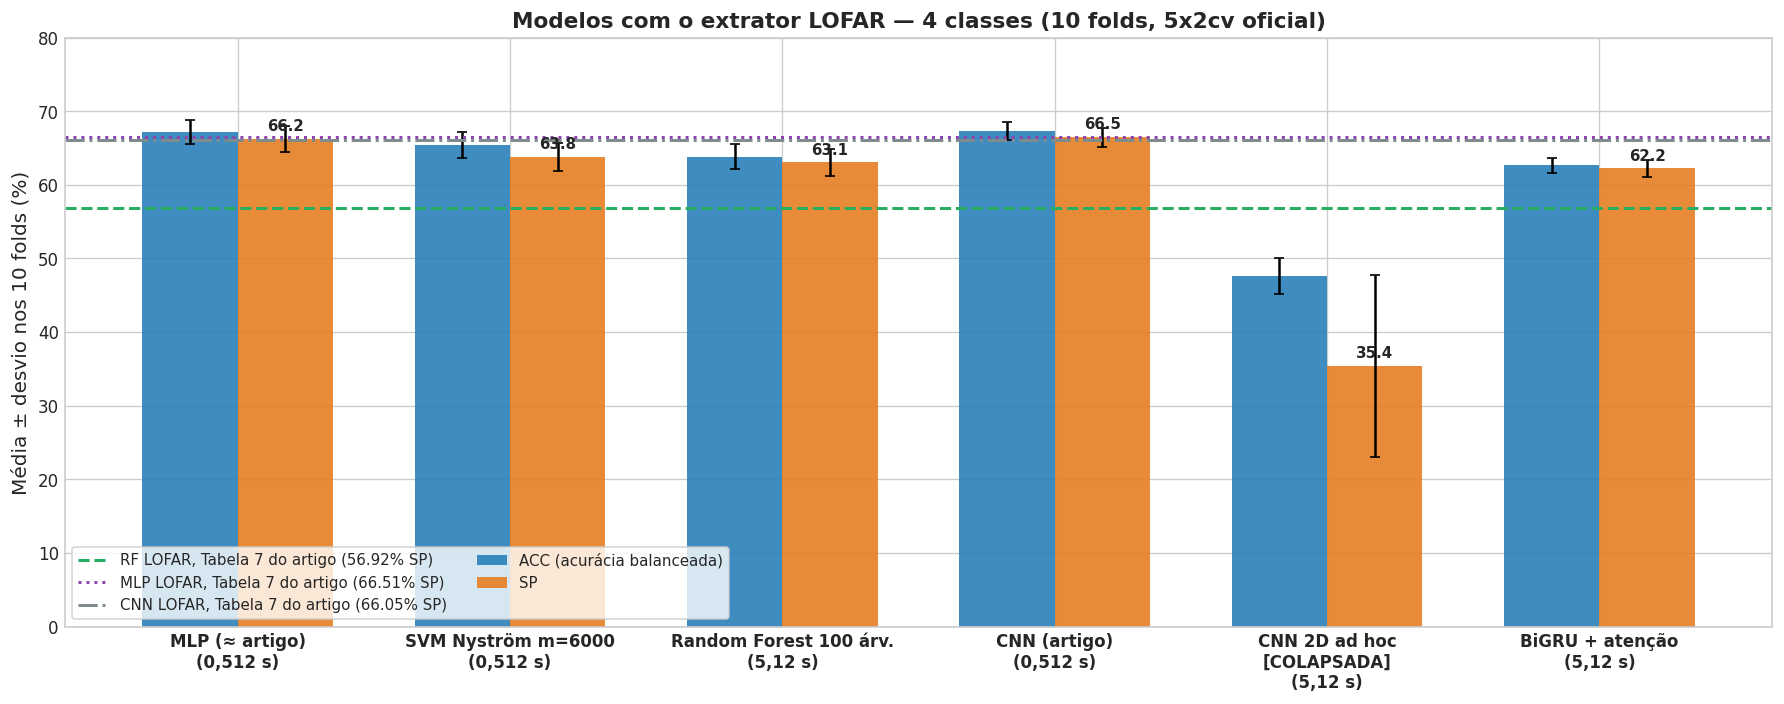

In [3]:
lbl = list(E4)
fig, ax = plt.subplots(figsize=(15, 6))
x = np.arange(len(lbl)); w = 0.35
ax.bar(x - w / 2, [S4[l]['ACC'][0] for l in lbl], w, yerr=[S4[l]['ACC'][1] for l in lbl], capsize=3,
       label='ACC (acurácia balanceada)', color='#2980b9', alpha=0.9)
r = ax.bar(x + w / 2, [S4[l]['SP'][0] for l in lbl], w, yerr=[S4[l]['SP'][1] for l in lbl], capsize=3,
           label='SP', color='#e67e22', alpha=0.9)
for rect in r:
    ax.annotate(f'{rect.get_height():.1f}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')
for (m, rr), cor, ls in zip([k for k in R.ARTICLE_TABLE7 if k[1] == REP], ['#27ae60', '#8e44ad', '#7f8c8d'], ['--', ':', '-.']):
    v = R.ARTICLE_TABLE7[(m, rr)]['SP'][0]
    ax.axhline(v, color=cor, ls=ls, lw=1.8, label=f'{m} {REP}, Tabela 7 do artigo ({v:.2f}% SP)')
ax.set_xticks(x); ax.set_xticklabels([l + ('\n[COLAPSADA]' if COLAPSADO[l] else '') + f'\n({g})' for l, (*_, g, _) in zip(lbl, PRINCIPAIS)],
                                     fontweight='bold')
ax.set_ylabel('Média ± desvio nos 10 folds (%)'); ax.set_ylim(0, 80)
ax.legend(loc='lower left', fontsize=9, ncol=2, frameon=True)
plt.title(f'Modelos com o extrator {REP} — 4 classes (10 folds, 5x2cv oficial)', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Varredura do SVM Nyström

O SVM Nyström (núcleo RBF aproximado por *landmarks*, `test_scripts/svm.py`) foi a família mais explorada no projeto. A tabela e o gráfico abaixo trazem todas as configurações com LOFAR puro que têm os 10 folds em disco (cascatas e híbridos ficam no Notebook 5 e em `reports/comparacao_modelos.md`):

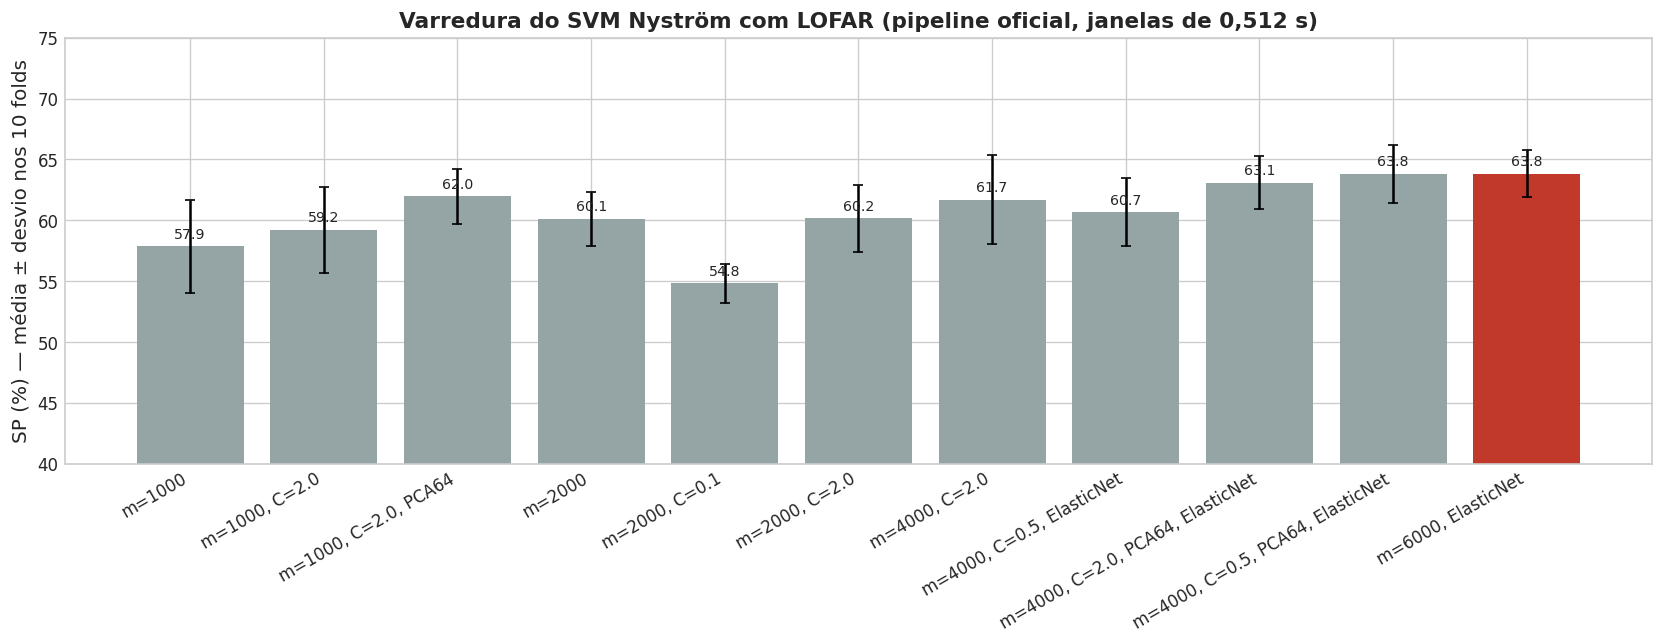

,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
m=1000,57.86 ± 3.83,60.95 ± 2.89,57.86 ± 3.53,27.42,53.09,77.38,85.92,svm_nystroem_1000_lofar
"m=1000, C=2.0",59.20 ± 3.55,61.35 ± 2.46,59.40 ± 3.48,36.12,48.72,76.17,84.39,svm_nystroem_1000_lofar_C2.0
"m=1000, C=2.0, PCA64",61.96 ± 2.22,63.16 ± 2.18,62.65 ± 1.74,44.83,50.81,75.28,81.73,svm_nystroem_1000_lofar_pca64_C2.0
m=2000,60.10 ± 2.25,62.54 ± 1.98,59.95 ± 2.77,34.04,54.90,75.61,85.61,svm_nystroem_2000_lofar
"m=2000, C=0.1",54.84 ± 1.60,59.67 ± 1.28,54.64 ± 1.69,17.98,54.97,79.02,86.73,svm_nystroem_2000_lofar_C0.1
"m=2000, C=2.0",60.15 ± 2.74,62.45 ± 2.17,60.59 ± 2.64,34.10,53.42,78.41,83.88,svm_nystroem_2000_lofar_C2.0
"m=4000, C=2.0",61.70 ± 3.67,63.55 ± 2.91,62.85 ± 3.33,43.43,50.81,78.55,81.43,svm_nystroem_4000_lofar_C2.0
"m=4000, C=0.5, ElasticNet",60.66 ± 2.78,63.23 ± 2.05,60.82 ± 2.47,31.18,58.05,78.27,85.41,svm_nystroem_4000_lofar_elasticnet_l1r0.15_C0.5
"m=4000, C=2.0, PCA64, ElasticNet",63.10 ± 2.19,64.04 ± 1.88,64.34 ± 2.23,47.64,55.97,74.91,77.65,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....


In [4]:
lbls = [l for l, _ in SVM_SWEEP]
fig, ax = plt.subplots(figsize=(14, 5.5))
sp = [SWEEP[l]['SP'][0] for l in lbls]; sd = [SWEEP[l]['SP'][1] for l in lbls]
best_sw = int(np.argmax(sp))
bars = ax.bar(range(len(lbls)), sp, yerr=sd, capsize=3, color=['#c0392b' if i == best_sw else '#95a5a6' for i in range(len(lbls))])
for b in bars:
    ax.annotate(f'{b.get_height():.1f}', xy=(b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 3),
                textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
ax.set_xticks(range(len(lbls))); ax.set_xticklabels(lbls, rotation=30, ha='right')
ax.set_ylim(40, 75); ax.set_ylabel('SP (%) — média ± desvio nos 10 folds')
ax.set_title(f'Varredura do SVM Nyström com {REP} (pipeline oficial, janelas de 0,512 s)', fontweight='bold')
plt.tight_layout()
plt.show()

display(tab_sweep)

* A melhor configuração é **m=6000, ElasticNet** (SP 63,83 ± 1,91%) e a pior, **m=2000, C=0.1** (SP 54,84 ± 1,60%). A diferença entre elas é significativa no F-test 5x2cv (F = 9,24, p = 0,012).
* 3 das outras 10 configurações ficam a menos de um desvio (1,91 p.p.) do SP médio da melhor; escolher uma "configuração campeã" só pelo SP médio não tem suporte estatístico sem o F-test.
* Ficaram fora da varredura, por não terem as predições dos 10 folds com o nome padrão em disco: m=6000, C=0.5, ElasticNet (`svm_nystroem_6000_lofar_elasticnet_l1r0.15_C0.5`), m=10000, ElasticNet (`svm_nystroem_10000_lofar_elasticnet_l1r0.15`), m=10000, C=0.5, ElasticNet (`svm_nystroem_10000_lofar_elasticnet_l1r0.15_C0.5`).

## 4. Recall por Classe

Recall médio nos 10 folds (modelos 4c):

,SMALL,MEDIUM,LARGE,BACKGROUND
MLP (≈ artigo),46.35,61.48,74.72,86.33
SVM Nyström m=6000,38.15,60.40,76.31,87.04
Random Forest 100 árv.,47.81,55.64,75.79,75.92
CNN (artigo),47.81,63.89,71.73,85.71
CNN 2D ad hoc,39.21,33.22,27.48,90.41
BiGRU + atenção,55.84,51.21,68.88,74.69


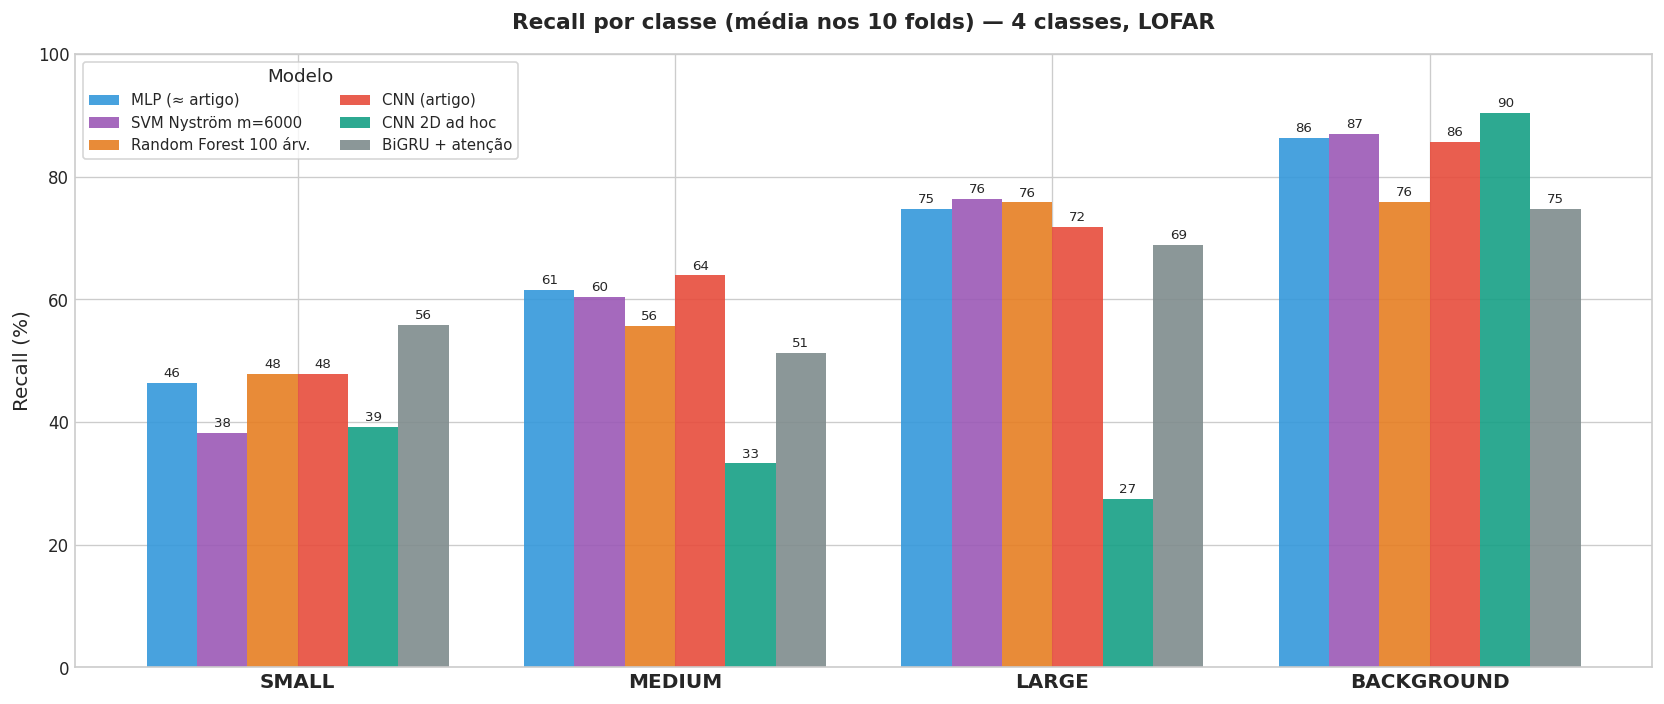

In [5]:
classes = R.CLASSES
recalls_matrix = np.array([[S4[l][f'R_{c}'][0] for c in classes] for l in E4])
display(pd.DataFrame(recalls_matrix.round(2), index=list(E4), columns=classes))
fig, ax = plt.subplots(figsize=(14, 6))
n = len(E4); width = 0.8 / n
cores = ['#3498db', '#9b59b6', '#e67e22', '#e74c3c', '#16a085', '#7f8c8d']
for i, (l, color) in enumerate(zip(E4, cores)):
    rects = ax.bar(np.arange(4) + (i - (n - 1) / 2) * width, recalls_matrix[i], width, label=l, color=color, alpha=0.9)
    for rect in rects:
        ax.annotate(f'{rect.get_height():.0f}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.set_title(f'Recall por classe (média nos 10 folds) — 4 classes, {REP}', fontweight='bold', pad=15)
ax.set_xticks(np.arange(4)); ax.set_xticklabels(classes, fontsize=12, fontweight='bold')
ax.set_ylabel('Recall (%)'); ax.set_ylim(0, 100)
ax.legend(title='Modelo', loc='upper left', frameon=True, fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

### Principais Fenômenos Observados (valores calculados acima e nas matrizes da seção 5):
1. **SMALL:** o maior recall entre os modelos não colapsados é o do BiGRU + atenção (55,84%). Classe de menor recall em cada modelo: MLP (≈ artigo): SMALL (46,35%); SVM Nyström m=6000: SMALL (38,15%); Random Forest 100 árv.: SMALL (47,81%); CNN (artigo): SMALL (47,81%); BiGRU + atenção: MEDIUM (51,21%).
2. **BACKGROUND:** o maior recall é o do SVM Nyström m=6000 (87,04%); no CNN (artigo), 7,8% do fundo vai para SMALL.
3. **Confusão SMALL → MEDIUM / LARGE** (matrizes acumuladas): MLP (≈ artigo): 21,2% / 25,4%; SVM Nyström m=6000: 22,8% / 28,7%; Random Forest 100 árv.: 20,4% / 30,6%; CNN (artigo): 23,1% / 22,3%; BiGRU + atenção: 16,8% / 24,7%.

## 5. Matrizes de Confusão Acumuladas nos 10 Folds ($5\times2$cv)

### 5.1 Problema de 4 Classes (SMALL, MEDIUM, LARGE, BACKGROUND)
Matrizes por arquivo, **acumuladas** nas 10 dobras (n = 6.390 instâncias arquivo × fold; cada arquivo aparece em média 3,75 vezes no teste) e normalizadas por linha. A diagonal acumulada difere ligeiramente do recall médio por fold da tabela.

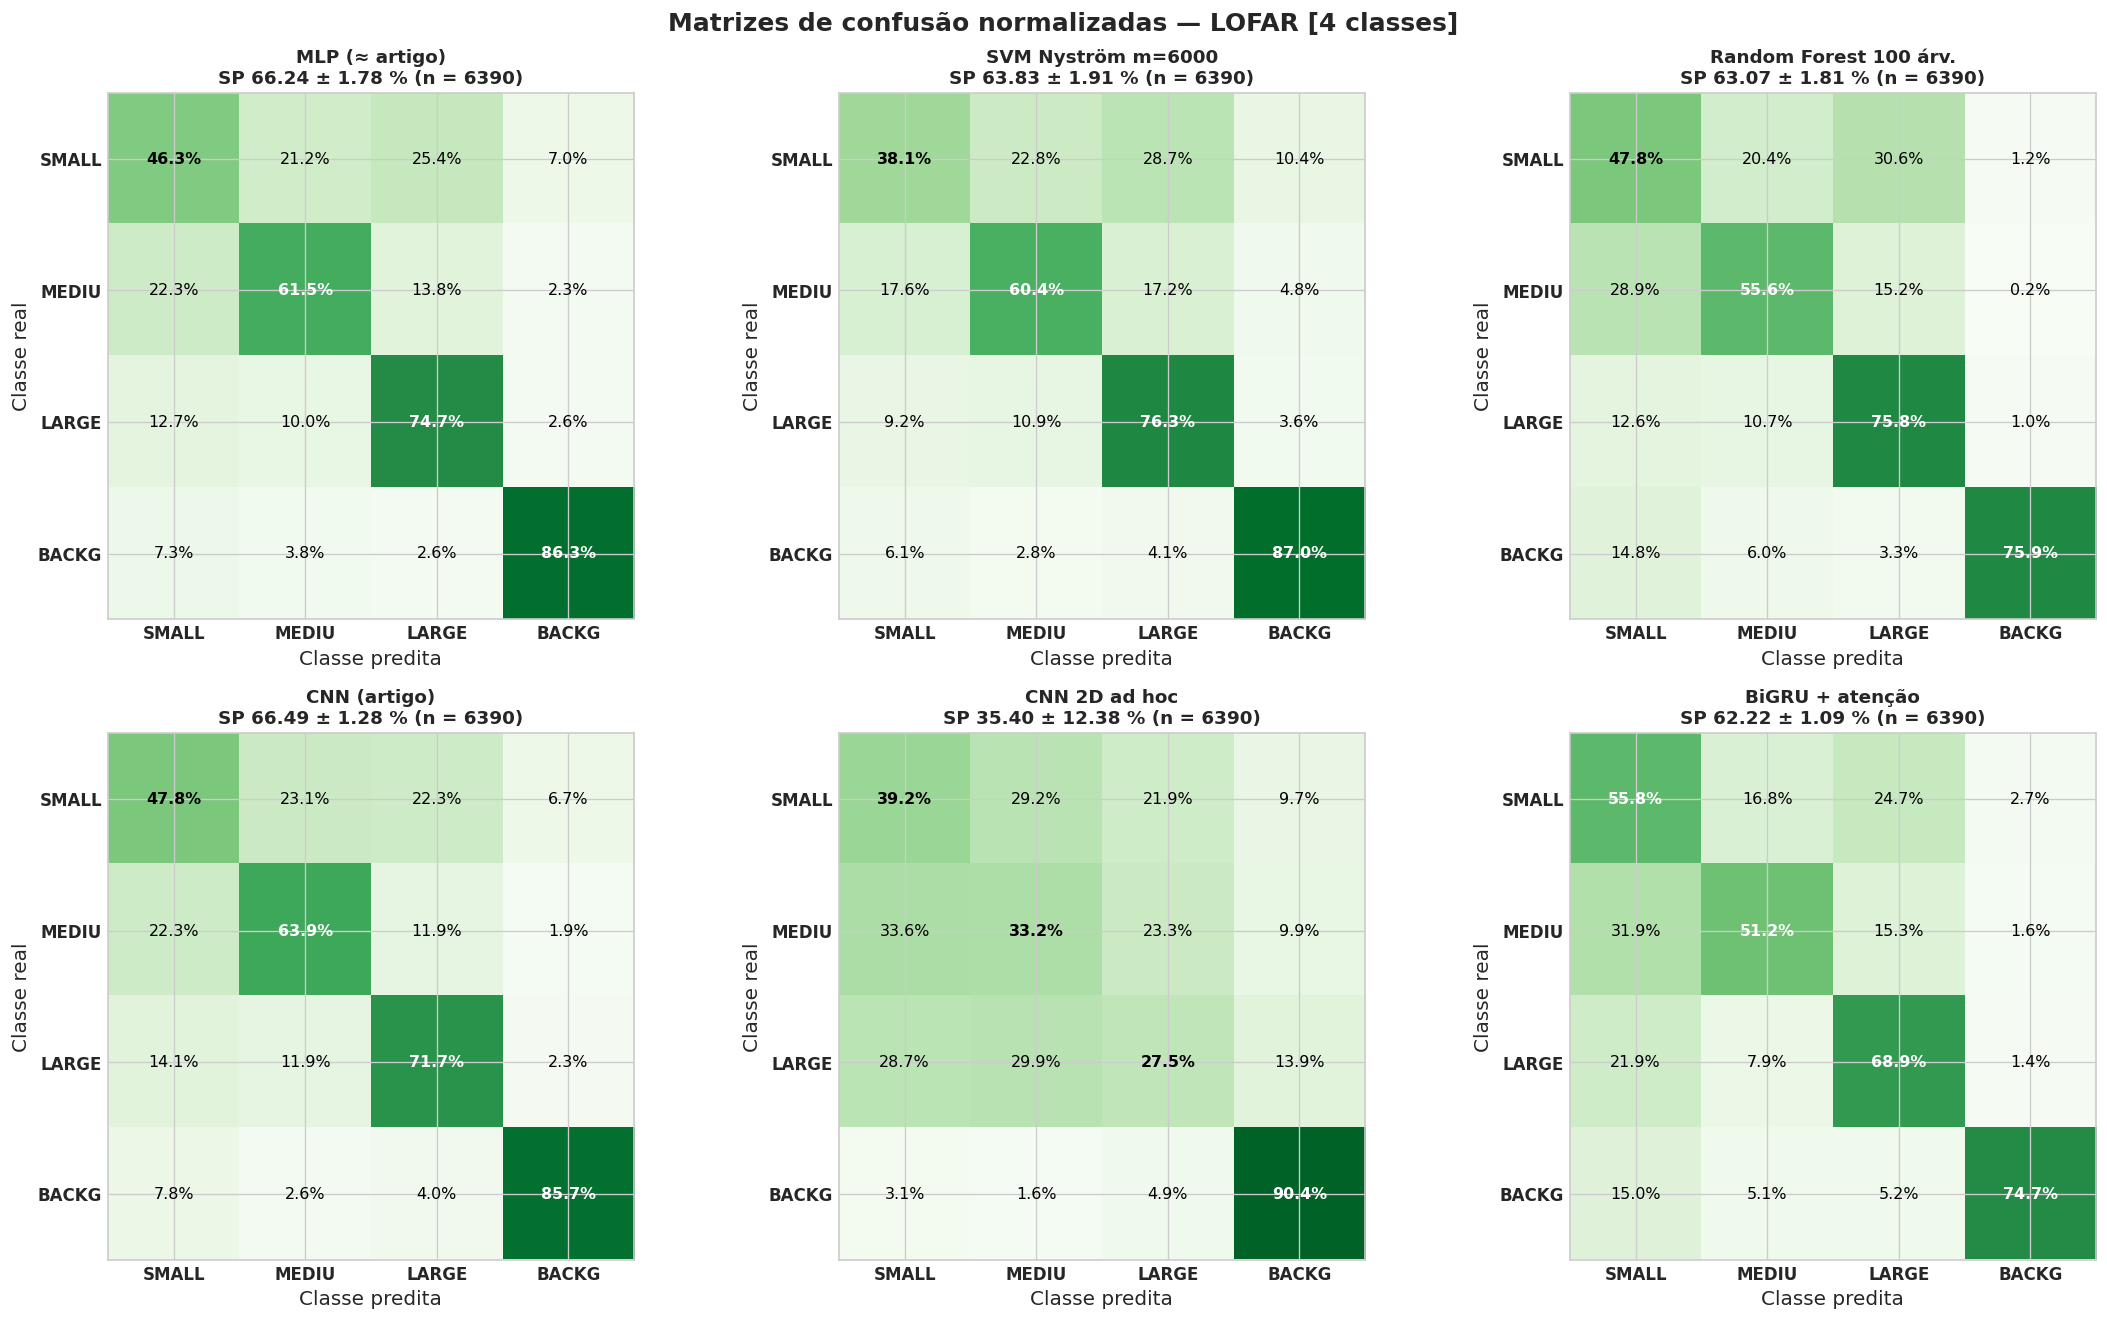

In [6]:
def confusion(exp):
    """Matriz de confusão por arquivo, ACUMULADA nas 10 dobras (instâncias arquivo x fold), normalizada por linha (%)."""
    df = pd.concat(R.file_predictions(exp).values(), ignore_index=True)
    rows = sorted(df.Target.unique())
    cols = sorted(set(rows) | set(df.Prediction.unique()))
    cm = pd.crosstab(df.Target, df.Prediction).reindex(index=rows, columns=cols, fill_value=0)
    cmn = 100 * cm.div(cm.sum(axis=1), axis=0)
    cmn.index = [R.CLASSES[i] for i in rows]; cmn.columns = [R.CLASSES[i] for i in cols]
    return cmn, int(cm.values.sum())


CM4 = {l: confusion(e) for l, e in E4.items()}
CM3 = {l: confusion(e) for l, e in E3.items()}
N_FILES = len(set().union(*[set(d.File) for d in R.file_predictions(E4[next(iter(E4))]).values()]))


def plot_cms(CMS, S, cmap, suptitle):
    n = len(CMS); ncol = min(n, 3); nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(6.2 * ncol, 5.6 * nrow), squeeze=False)
    for ax in axes.flatten()[n:]:
        ax.axis('off')
    for ax, (l, (cm, nn)) in zip(axes.flatten(), CMS.items()):
        sp = S[l]['SP']
        im = ax.imshow(cm.values, cmap=cmap, vmin=0, vmax=100)
        ax.set_title(f'{l}\nSP {sp[0]:.2f} ± {sp[1]:.2f} % (n = {nn})', fontsize=11, fontweight='bold')
        ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels([c[:5] for c in cm.columns], fontweight='bold')
        ax.set_yticks(range(cm.shape[0])); ax.set_yticklabels([c[:5] for c in cm.index], fontweight='bold')
        ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                v = cm.values[i, j]
                ax.text(j, i, f'{v:.1f}%', ha='center', va='center', color='white' if v > 50 else 'black',
                        fontweight='bold' if i == j else 'normal', fontsize=9.5)
    plt.suptitle(suptitle, fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_cms(CM4, S4, 'Greens', f'Matrizes de confusão normalizadas — {REP} [4 classes]')

### 5.2 Modelos Retreinados sem BACKGROUND (3c: SMALL, MEDIUM, LARGE)

Só BiGRU + atenção tem versão retreinada sem BACKGROUND com LOFAR. É outro problema (3 classes): os números não são comparáveis aos modelos 4c nem ao modo `4c_sem_bg`.

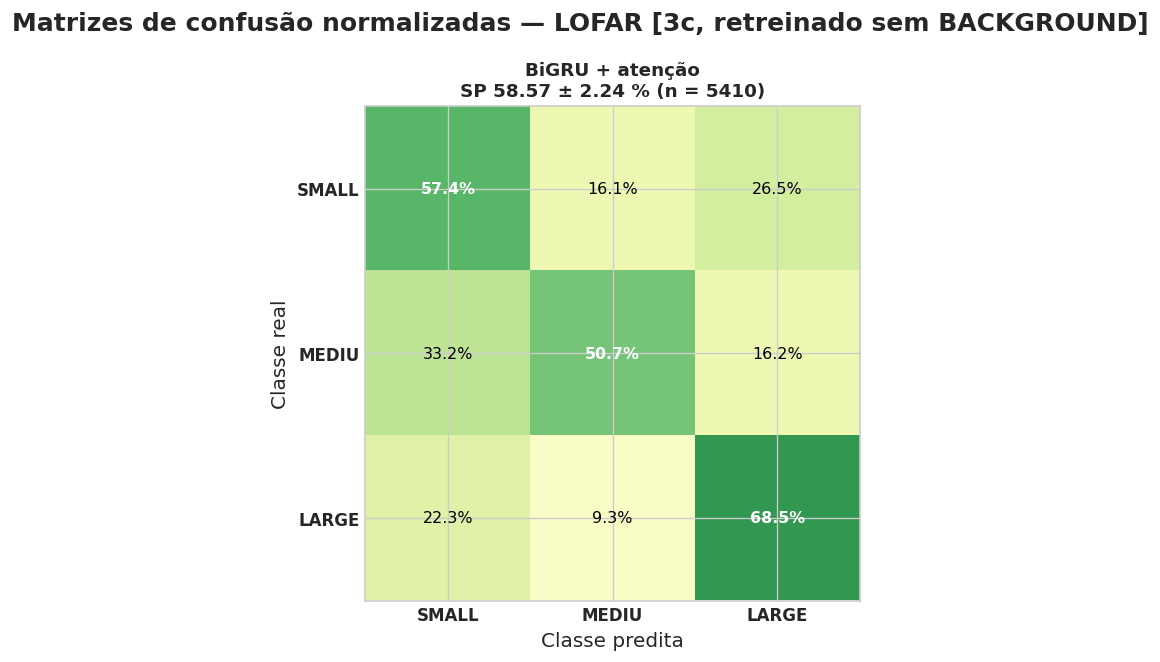

In [7]:
plot_cms(CM3, S3, 'YlGn', f'Matrizes de confusão normalizadas — {REP} [3c, retreinado sem BACKGROUND]')

* **BiGRU + atenção:** SP 3c 58,57 ± 2,24% (no 4c: 62,22 ± 1,09%); recall de SMALL 57,42% (no 4c: 55,84%); SMALL → LARGE 26,5% e SMALL → MEDIUM 16,1%.

## 6. Testes Estatísticos (F-test 5x2cv)

Toda afirmação de "supera" abaixo depende deste teste (Alpaydin, 1999; o mesmo usado no artigo). Primeiro, o melhor modelo LOFAR em SP médio contra os demais; depois, LOFAR × MEL no mesmo classificador:

In [8]:
# F-test 5x2cv combinado (Alpaydin, 1999), como no artigo, sobre o SP por fold (modelos 4c)
ORDEM = sorted(E4, key=lambda l: -S4[l]['SP'][0])
MELHOR = ORDEM[0]
rows = []
for b in ORDEM[1:]:
    F, p = R.f_test_5x2(E4[MELHOR], E4[b])
    rows.append({'A': MELHOR, 'B': b, 'SP A': round(S4[MELHOR]['SP'][0], 2), 'SP B': round(S4[b]['SP'][0], 2),
                 'F': round(F, 2), 'p': round(p, 4), 'p < 0,05': p < 0.05})
df_tests = pd.DataFrame(rows)
print(f'Melhor modelo {REP} (SP médio) contra os demais:')
display(df_tests)

rows = []
for arq, a, b in PARES_OUTRA:
    sa, sb = R.summary(a), R.summary(b)
    F, p = R.f_test_5x2(a, b)
    Fs, ps = R.f_test_5x2(a, b, metric='R_SMALL')
    rows.append({'Arquitetura': arq, f'SP {REP}': R.fmt(sa['SP']), f'SP {OUTRA}': R.fmt(sb['SP']),
                 'Δ SP (p.p.)': round(sa['SP'][0] - sb['SP'][0], 2), 'p (SP)': round(p, 4),
                 f'R_SMALL {REP}': round(sa['R_SMALL'][0], 2), f'R_SMALL {OUTRA}': round(sb['R_SMALL'][0], 2),
                 'p (R_SMALL)': round(ps, 4), 'exp A': a, 'exp B': b})
df_outra = pd.DataFrame(rows).set_index('Arquitetura')
print(f'{REP} × {OUTRA} no mesmo classificador:')
display(df_outra.drop(columns=['exp A', 'exp B']))

Melhor modelo LOFAR (SP médio) contra os demais:


,A,B,SP A,SP B,F,p,"p < 0,05"
0,CNN (artigo),MLP (≈ artigo),66.49,66.24,0.67,0.7234,False
1,CNN (artigo),SVM Nyström m=6000,66.49,63.83,2.27,0.1896,False
2,CNN (artigo),Random Forest 100 árv.,66.49,63.07,4.72,0.0502,False
3,CNN (artigo),BiGRU + atenção,66.49,62.22,16.75,0.0031,True
4,CNN (artigo),CNN 2D ad hoc,66.49,35.40,7.05,0.0218,True


LOFAR × MEL no mesmo classificador:


,SP LOFAR,SP MEL,Δ SP (p.p.),p (SP),R_SMALL LOFAR,R_SMALL MEL,p (R_SMALL)
Arquitetura,,,,,,,
"MLP (≈ artigo, 0,512 s)",66.24 ± 1.78,64.74 ± 2.05,1.51,0.6530,46.35,44.78,0.4886
"CNN (artigo, 0,512 s)",66.49 ± 1.28,65.53 ± 1.73,0.95,0.2216,47.81,47.42,0.7596
SVM Nyström (melhor de cada),63.83 ± 1.91,63.78 ± 1.14,0.05,0.0960,38.15,50.73,0.2630
"Random Forest (5,12 s)",63.07 ± 1.81,61.50 ± 1.89,1.57,0.6374,47.81,57.87,0.0317
"BiGRU + atenção (5,12 s)",62.22 ± 1.09,63.60 ± 1.53,-1.38,0.2137,55.84,45.28,0.2349


## 7. Diagnóstico Científico e Conclusões

### 7.1 O melhor modelo LOFAR
* Em SP médio, o melhor é **CNN (artigo)** (66,49 ± 1,28%), que é significativamente melhor que BiGRU + atenção, CNN 2D ad hoc e equivalente a MLP (≈ artigo), SVM Nyström m=6000, Random Forest 100 árv..
* A maior diferença de SP médio **sem** significância é de 3,42 p.p. (CNN (artigo) × Random Forest 100 árv.): a ordem do ranking da seção 1 **não** deve ser lida como hierarquia.

* Referência do projeto: a MLP LOFAR (artigo 66,51 ± 1,39%; local 66,24 ± 1,78%). O melhor LOFAR contra a MLP LOFAR local: F-test p = 0,723 (**não** significativa).

### 7.2 LOFAR × MEL no mesmo classificador

| Arquitetura | SP LOFAR | SP MEL | Δ (p.p.) | p (SP) | R_SMALL LOFAR | R_SMALL MEL | p (R_SMALL) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| MLP (≈ artigo, 0,512 s) | 66,24 ± 1,78 | 64,74 ± 2,05 | 1,51 | 0,653 | 46,35 | 44,78 | 0,489 |
| CNN (artigo, 0,512 s) | 66,49 ± 1,28 | 65,53 ± 1,73 | 0,95 | 0,222 | 47,81 | 47,42 | 0,760 |
| SVM Nyström (melhor de cada) | 63,83 ± 1,91 | 63,78 ± 1,14 | 0,05 | 0,096 | 38,15 | 50,73 | 0,263 |
| Random Forest (5,12 s) | 63,07 ± 1,81 | 61,50 ± 1,89 | 1,57 | 0,637 | 47,81 | 57,87 | 0,032 |
| BiGRU + atenção (5,12 s) | 62,22 ± 1,09 | 63,60 ± 1,53 | -1,38 | 0,214 | 55,84 | 45,28 | 0,235 |

* A diferença de SP entre LOFAR e MEL é significativa (p < 0,05) em: **nenhuma** arquitetura.
* No recall de SMALL, a diferença é significativa em: Random Forest (5,12 s) (LOFAR 47,81% × MEL 57,87%, p = 0,032).
* No artigo, a ordem entre LOFAR e MEL também depende do classificador (Tabela 7: RF favorece o MEL; MLP e CNN favorecem o LOFAR).

### 7.3 O que estes resultados permitem dizer
1. Os números do pipeline oficial reproduzem os do artigo dentro do desvio entre folds (seção 1), o que dá base para as comparações locais.
2. Os modelos ad hoc de 5,12 s não são uma reprodução do artigo: mudam a grade temporal **e** a implementação; servem para comparar representações (LOFAR, MEL, DEMON, HHT) no mesmo classificador, como nos Notebooks 9, 11 e 12.
3. Afirmações de superioridade entre modelos LOFAR só valem quando o F-test da seção 6 dá p < 0,05.